# code_098 · Factorization and the signal that variance misses

**Book:** section 20.1. A self-contained representation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_20_GUIDE.md), [run evidence](../CHAPTER_20_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_098).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2098;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2098


<a id="contracts"></a>
 ## Four objectives, one information boundary
 Generate positive energies from two independent exponential sources and three mixed channels. A binary pattern adds a small vector orthogonal to the dominant mixing plane. Training/development/final sizes are 300/80/200. Development is diagnostic only; rank two is declared beforehand. All three channels share units. PCA centers but does not standardize. NMF sees positive uncentered energies, including an offset: its rank budget therefore serves a different objective. ICA rotations/signs do not identify physical sources without additional evidence.


,method,train_MSE,development_MSE,final_MSE
0,PCA,0.000986,0.000976,0.001029
1,NMF,0.003362,0.004311,0.004173
2,ICA,0.000986,0.000976,0.001029


Retained counterfactual signal norm fraction: 0.0017358678171519022


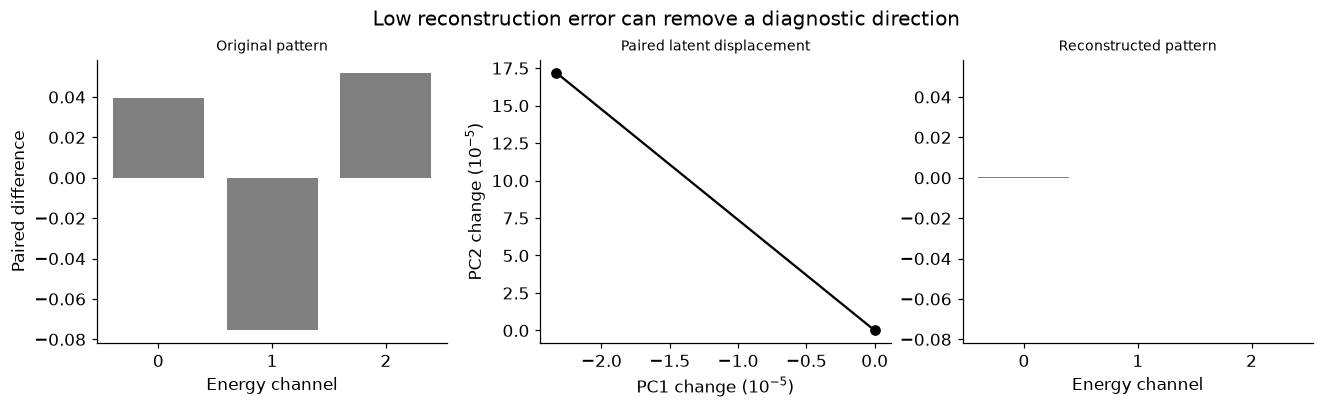

In [2]:
from sklearn.decomposition import PCA,NMF,FastICA
mixing=np.array([[1.,.8,.4],[.2,1.,1.3]])
v=np.linalg.svd(mixing,full_matrices=True)[2][-1];assert np.allclose(mixing@v,0)
def sample(n):
    s=rng.exponential(1.,(n,2));y=rng.integers(0,2,n)
    return 1+s@mixing+.1*y[:,None]*v+rng.normal(0,.02,(n,3)),y
train,ytrain=sample(300);dev,ydev=sample(80);final,yfinal=sample(200)
assert train.min()>0 and final.min()>0
models={'PCA':PCA(2,svd_solver='full'),'NMF':NMF(2,init='nndsvda',max_iter=2000,tol=1e-5,random_state=SEED),'ICA':FastICA(2,whiten='unit-variance',whiten_solver='svd',max_iter=2000,tol=1e-5,random_state=SEED)}
rows=[];recon={}
for name,model in models.items():
    z=model.fit_transform(train);recon[name]=model.inverse_transform(model.transform(final))
    rows.append({'method':name,'train_MSE':float(np.mean((train-model.inverse_transform(z))**2)),'development_MSE':float(np.mean((dev-model.inverse_transform(model.transform(dev)))**2)),'final_MSE':float(np.mean((final-recon[name])**2))})
pc=models['PCA'];centered=train-train.mean(0);u,s,vt=np.linalg.svd(centered,full_matrices=False)
np.testing.assert_allclose(pc.inverse_transform(pc.transform(train)),(u[:,:2]*s[:2])@vt[:2]+train.mean(0),atol=1e-10)
np.testing.assert_allclose(pc.transform(final),(final-pc.mean_)@pc.components_.T,atol=1e-10)
assert models['NMF'].components_.min()>=0 and models['NMF'].transform(train).min()>=0
pair=np.array([1+np.array([1.,1.])@mixing,1+np.array([1.,1.])@mixing+.1*v])
restored=pc.inverse_transform(pc.transform(pair));attenuation=float(np.linalg.norm(restored[1]-restored[0])/.1)
np.testing.assert_allclose(recon['PCA'],recon['ICA'],atol=1e-9)
RESULTS.update(metrics=rows,explained_variance_fraction=float(pc.explained_variance_ratio_.sum()),pattern_retained_fraction=attenuation,nmf_iterations=int(models['NMF'].n_iter_),ica_iterations=int(models['ICA'].n_iter_),pattern_vector=v.tolist(),split_sizes=[300,80,200])
display(pd.DataFrame(rows));print('Retained counterfactual signal norm fraction:',attenuation)
fig,axes=plt.subplots(1,3,figsize=(12,3.6))
axes[0].bar(range(3),pair[1]-pair[0],color='.5');axes[0].set(title='Original pattern',xlabel='Energy channel',ylabel='Paired difference')
z=pc.transform(pair);z=(z-z[0])*1e5;axes[1].plot(z[:,0],z[:,1],'o-',color='black');axes[1].set(title='Paired latent displacement',xlabel='PC1 change ($10^{-5}$)',ylabel='PC2 change ($10^{-5}$)')
axes[2].bar(range(3),restored[1]-restored[0],color='.5');axes[2].set(title='Reconstructed pattern',xlabel='Energy channel');axes[2].set_ylim(axes[0].get_ylim())
fig.suptitle('Low reconstruction error can remove a diagnostic direction');plt.show()


<a id="interpretation"></a>
 ## Reconstruction is not target sufficiency
 Compare losses in the original energy coordinates. ICA uses the same retained two-dimensional PCA subspace here, so rotating it cannot restore a discarded third direction. The counterfactual pair is a noiseless generator audit, not a fitted classifier or a causal claim about field damage. Nonnegative components remain nonunique. Changing units would change the unstandardized PCA objective; that is an engineering choice, not an automatic preprocessing rule.


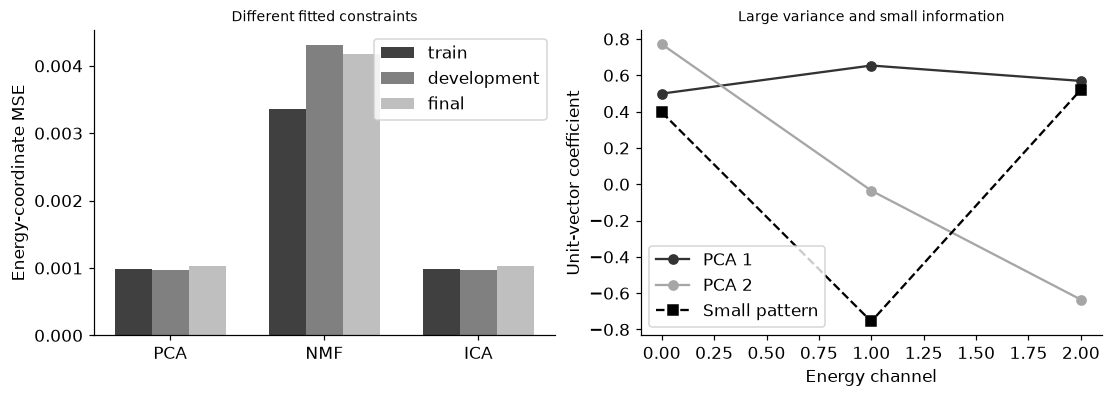

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
xx=np.arange(3)
for i,key in enumerate(['train_MSE','development_MSE','final_MSE']):axes[0].bar(xx+(i-1)*.24,[r[key] for r in rows],.24,label=key.replace('_MSE',''),color=str(.25+i*.25))
axes[0].set(xticks=xx,xticklabels=list(models),ylabel='Energy-coordinate MSE',title='Different fitted constraints');axes[0].legend()
for j,component in enumerate(pc.components_):axes[1].plot(range(3),component,'o-',color=str(.2+j*.45),label=f'PCA {j+1}')
axes[1].plot(range(3),v,'s--',color='black',label='Small pattern');axes[1].set(xlabel='Energy channel',ylabel='Unit-vector coefficient',title='Large variance and small information');axes[1].legend();plt.show()
assert np.isfinite(np.array([r['final_MSE'] for r in rows])).all()


In [4]:
summary={'example_id':'code_098','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['centered PCA/SVD identity', 'nonnegative factorization', 'independent components', 'small-signal attenuation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["centered PCA/SVD identity", "nonnegative factorization", "independent components", "small-signal attenuation"], "elapsed_seconds": 0.385, "example_id": "code_098", "hardware": "Darwin arm64 CPU", "results": {"explained_variance_fraction": 0.999329677432988, "ica_iterations": 6, "metrics": [{"development_MSE": 0.0009755213914827486, "final_MSE": 0.0010289636611159616, "method": "PCA", "train_MSE": 0.000986242129132029}, {"development_MSE": 0.004310845959388441, "final_MSE": 0.004172736393385739, "method": "NMF", "train_MSE": 0.0033621249875766352}, {"development_MSE": 0.0009755213914827463, "final_MSE": 0.001028963661115962, "method": "ICA", "train_MSE": 0.000986242129132029}], "nmf_iterations": 421, "pattern_retained_fraction": 0.0017358678171519022, "pattern_vector": [0.3966366510671125, -0.7560886160966829, 0.5205856045255848], "split_sizes": [300, 80, 200]}, "seed": 2098, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "panda